# Normalization

- to change the values of numeric columns in the dataset to use a common scale, without distorting differences in the ranges of values or losing information.

- types:
- minmax scaling
- mean normalization
- max abssolute scaling
- robust scaling

# 1. MinMax Scaling

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn  as sns 

In [2]:
df= pd.read_csv("wine.csv", sep=";")
df.sample(5)

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
612,6.3,0.25,0.53,1.8,0.021,41.0,101.0,0.989315,3.19,0.31,13,6
406,6.4,0.15,0.44,1.2,0.043,67.0,150.0,0.990700,3.14,0.73,11.2,7
919,7.1,0.31,0.38,1.2,0.036,10.0,124.0,0.992400,3.14,0.44,9.9,6
1147,7.1,0.30,0.46,1.5,0.066,29.0,133.0,0.990600,3.12,0.54,12.7,6
1003,7.7,0.26,0.34,6.4,0.050,36.0,163.0,0.993700,3.19,0.70,11.5,6


<Axes: xlabel='pH', ylabel='Density'>

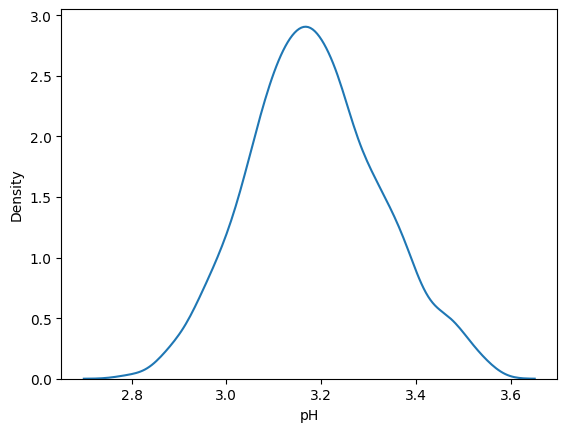

In [3]:
sns.kdeplot(df['pH'])

In [4]:
df.dtypes

fixed_acidity           float64
volatile_acidity        float64
citric_acid             float64
residual_sugar          float64
chlorides               float64
free_sulfur_dioxide     float64
total_sulfur_dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                  object
quality                   int64
dtype: object

In [5]:
df['alcohol']= pd.to_numeric(df['alcohol'],errors="coerce")

In [6]:
df['alcohol'].dtype

dtype('float64')

<Axes: xlabel='alcohol', ylabel='Density'>

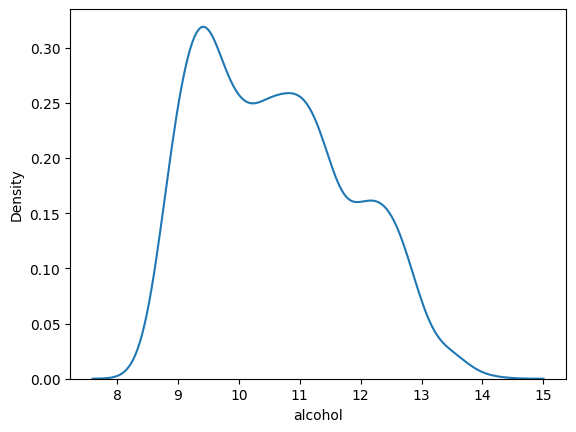

In [7]:
sns.kdeplot(df['alcohol'])

In [8]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train,y_test= train_test_split(
    df.drop('quality',axis=1),
    df['quality'],
    test_size=0.3,
    random_state=0
)

X_train.shape, X_test.shape

((1425, 11), (612, 11))

In [9]:
from sklearn.preprocessing import MinMaxScaler
scaler= MinMaxScaler()

#fit only the Trainset but 
scaler.fit(X_train)

#Transform both train and test sets 
X_train_scaled=scaler.transform(X_train)
X_test_scaled=scaler.transform(X_test)


In [10]:
X_train_scaled= pd.DataFrame(X_train_scaled,columns=X_train.columns)
X_test_scaled=pd.DataFrame(X_test_scaled,columns=X_test.columns)

In [11]:
np.round(X_train.describe(),1) # Before Normalizing

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol
count,1425.0,1425.0,1425.0,1425.0,1425.0,1425.0,1425.0,1425.0,1425.0,1425.0,1416.0
mean,6.8,0.3,0.3,6.2,0.0,34.5,136.7,1.5,3.2,0.5,10.6
std,0.8,0.1,0.1,4.8,0.0,15.2,41.6,7.0,0.1,0.1,1.2
min,4.4,0.1,0.0,0.7,0.0,3.0,28.0,1.0,2.8,0.2,8.4
25%,6.3,0.2,0.3,1.8,0.0,23.5,106.0,1.0,3.1,0.4,9.5
50%,6.8,0.3,0.3,5.2,0.0,34.0,132.0,1.0,3.2,0.5,10.5
75%,7.3,0.3,0.4,9.2,0.0,45.0,166.0,1.0,3.3,0.5,11.5
max,8.8,0.5,0.6,20.8,0.1,78.0,253.0,100.1,3.6,0.8,14.2


In [12]:
np.round(X_train_scaled.describe(),1) # After normalizing
# The min and ,max values of all the columns became o and 1 .. that is generally the purpose of the normaalization..

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol
count,1425.0,1425.0,1425.0,1425.0,1425.0,1425.0,1425.0,1425.0,1425.0,1425.0,1416.0
mean,0.6,0.5,0.6,0.3,0.5,0.4,0.5,0.0,0.5,0.5,0.4
std,0.2,0.2,0.2,0.2,0.2,0.2,0.2,0.1,0.2,0.2,0.2
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,0.4,0.3,0.5,0.1,0.4,0.3,0.3,0.0,0.4,0.4,0.2
50%,0.5,0.4,0.5,0.2,0.5,0.4,0.5,0.0,0.5,0.5,0.4
75%,0.7,0.6,0.7,0.4,0.6,0.6,0.6,0.0,0.6,0.6,0.5
max,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


Text(0.5, 1.0, 'After Scaling: Alcohol')

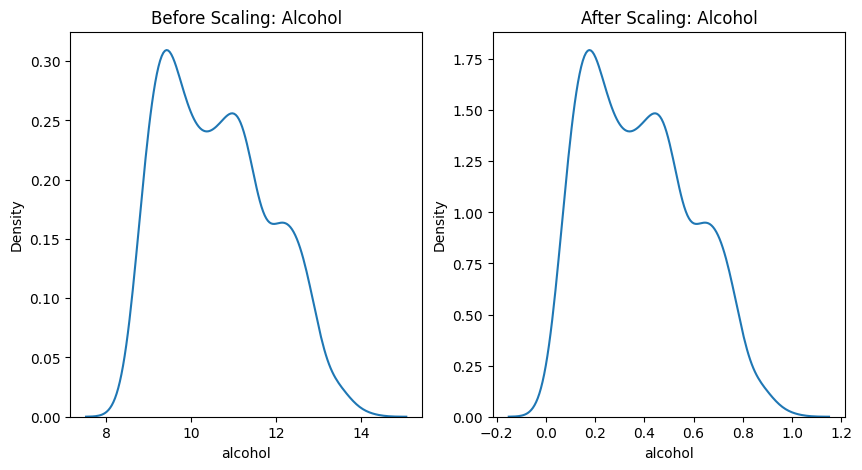

In [13]:
import matplotlib.pyplot as plt

# Compare one feature before and after scaling
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
sns.kdeplot(X_train['alcohol'])
plt.title("Before Scaling: Alcohol")

plt.subplot(1, 2, 2)
sns.kdeplot(X_train_scaled["alcohol"])
plt.title("After Scaling: Alcohol")



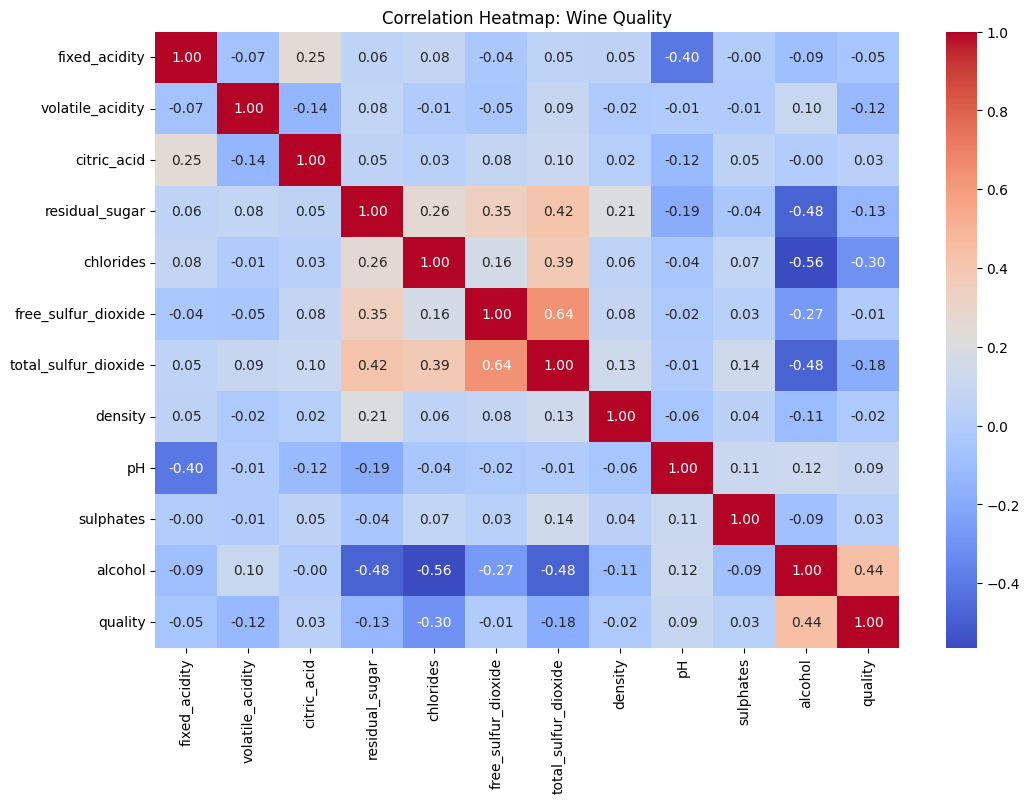

In [14]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap: Wine Quality")
plt.show()

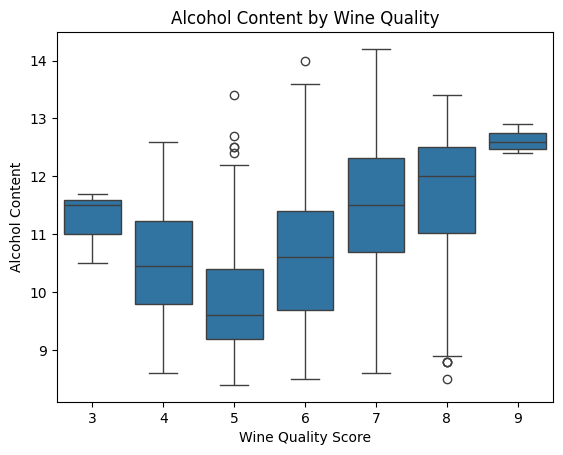

In [15]:
sns.boxplot(data=df, x="quality", y="alcohol")

plt.title("Alcohol Content by Wine Quality")
plt.xlabel("Wine Quality Score")
plt.ylabel("Alcohol Content")
plt.show()

In [16]:
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

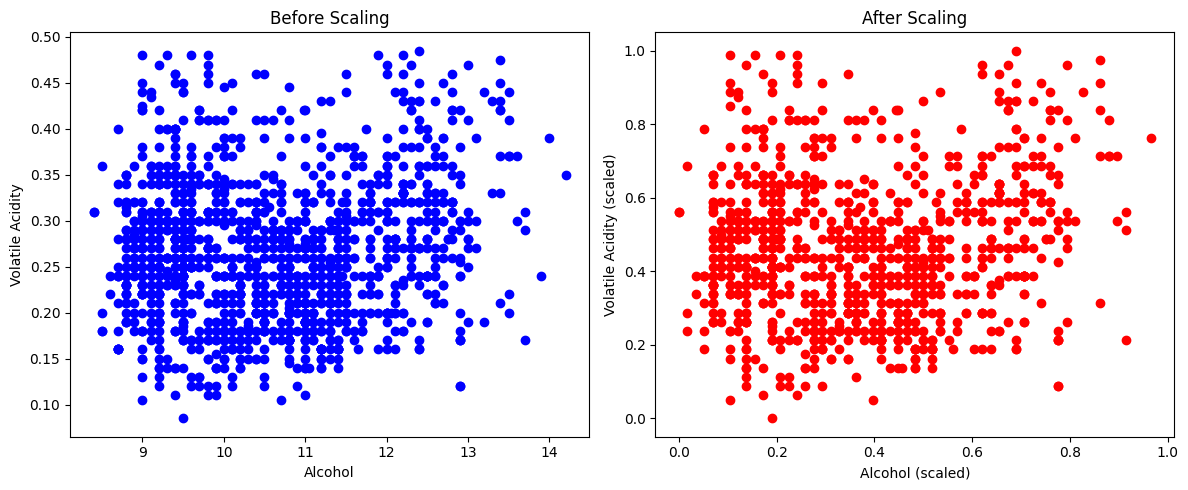

In [17]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

# Before scaling
ax1.scatter(X_train["alcohol"], X_train["volatile_acidity"],c="blue")
ax1.set_title("Before Scaling")
ax1.set_xlabel("Alcohol")
ax1.set_ylabel("Volatile Acidity")

# After scaling
ax2.scatter(
    X_train_scaled["alcohol"],
    X_train_scaled["volatile_acidity"],
c="red")
ax2.set_title("After Scaling")
ax2.set_xlabel("Alcohol (scaled)")
ax2.set_ylabel("Volatile Acidity (scaled)")

plt.tight_layout()
plt.show()

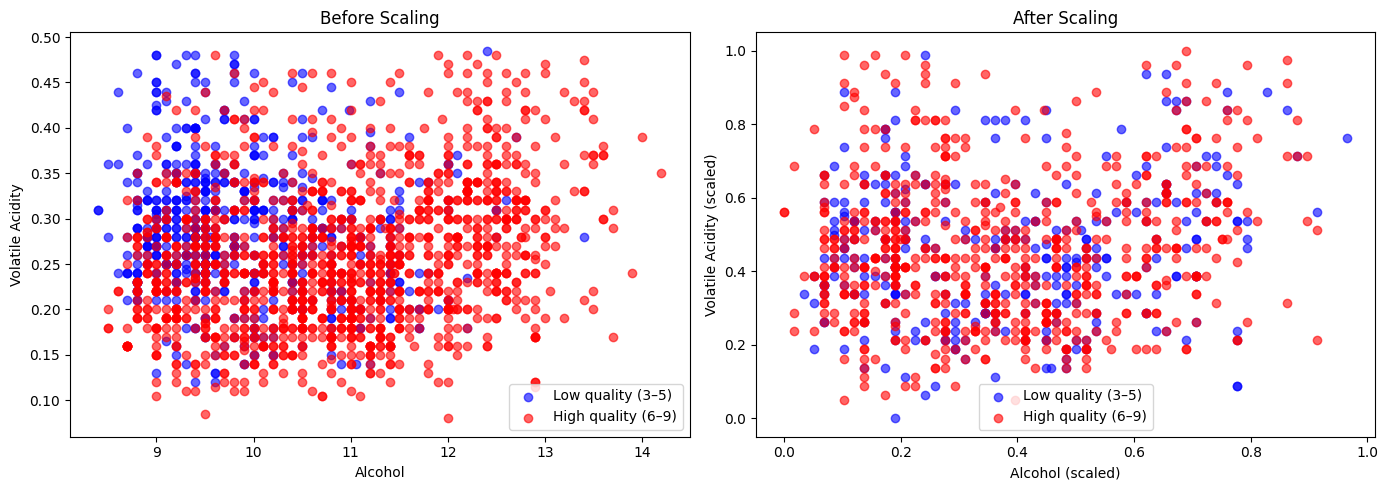

In [19]:
import matplotlib.pyplot as plt

# Split wine samples into two quality groups
low_quality = df[df["quality"] <= 5]
high_quality = df[df["quality"] >= 6]

fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(14, 5))

# Before scaling
ax1.scatter(
    low_quality["alcohol"],
    low_quality["volatile_acidity"],
    color="blue",
    label="Low quality (3–5)",
    alpha=0.6
)

ax1.scatter(
    high_quality["alcohol"],
    high_quality["volatile_acidity"],
    color="red",
    label="High quality (6–9)",
    alpha=0.6
)

ax1.set_title("Before Scaling")
ax1.set_xlabel("Alcohol")
ax1.set_ylabel("Volatile Acidity")
ax1.legend()

# After scaling
# Use the same row indices to align quality labels with scaled features
low_idx = X_train.index.intersection(low_quality.index)
high_idx = X_train.index.intersection(high_quality.index)

ax2.scatter(
    X_train_scaled.loc[low_idx, "alcohol"],
    X_train_scaled.loc[low_idx, "volatile_acidity"],
    color="blue",
    label="Low quality (3–5)",
    alpha=0.6
)

ax2.scatter(
    X_train_scaled.loc[high_idx, "alcohol"],
    X_train_scaled.loc[high_idx, "volatile_acidity"],
    color="red",
    label="High quality (6–9)",
    alpha=0.6
)

ax2.set_title("After Scaling")
ax2.set_xlabel("Alcohol (scaled)")
ax2.set_ylabel("Volatile Acidity (scaled)")
ax2.legend()

plt.tight_layout()
plt.show()

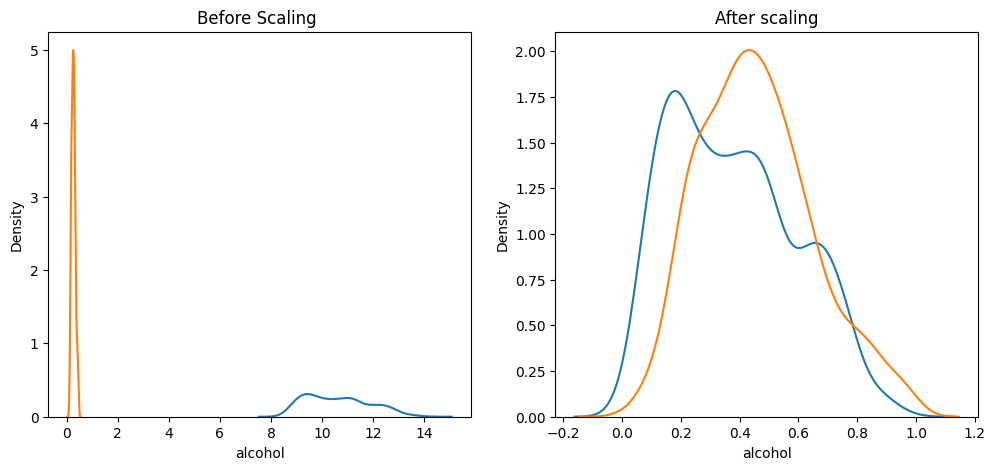

In [21]:
fig, (ax1, ax2)= plt.subplots(ncols=2, figsize=(12,5))

# Before Scaling
ax1.set_title("Before Scaling ")
sns.kdeplot(X_train['alcohol'], ax=ax1)
sns.kdeplot(X_train['volatile_acidity'], ax=ax1)

#After Scaling
ax2.set_title("After scaling")
sns.kdeplot(X_train_scaled["alcohol"], ax=ax2)
sns.kdeplot(X_train_scaled['volatile_acidity'],ax=ax2)

plt.show()

- That are the general methods of the minmax scaling .. Some other techniques of normalization are:
# Mean Normalization
- used in centred data but very lessly used ..

# MaxAbsScaling
  - used in sparse data(when there is more zeros)

# Robust Scaling
- Robust to outliers .so use when we have a lot of outliers in dataset.

# Comparision 

# Normalization Vs Standarization
- Most of the problems uses standarization ..
- ### Minmax is used when the data is given with the min and max value .
- ### If there are a lot of outliers , we can use the robust scaling ..
- ### If there are a lot of zeros we can use the maxAbs scaling 

# But first we need to see if we really have to do the feature scaling .. If we are working in DecisionTreeClassifier we dont need any scaling .